# This notebook generates the alignment matrix for 3D SMLM measurements

In [2]:
import math
from pathlib import Path

import locan

%matplotlib inline
import sys
sys.path.append('E:\Receptor_Quantification\SMLM_analysis')
import ReceptorQ as rq
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import trackpy as tp
import napari
tp.quiet(True) # hide status messages
import locan as lc
from locan.data.locdata import LocData
import math
from pathlib import Path
import cv2

<>:8: SyntaxWarning: invalid escape sequence '\R'
<>:8: SyntaxWarning: invalid escape sequence '\R'
C:\Users\ris82dr\AppData\Local\Temp\ipykernel_29220\4241543798.py:8: SyntaxWarning: invalid escape sequence '\R'
  sys.path.append('E:\Receptor_Quantification\SMLM_analysis')


In [3]:
lc.show_versions(system=False, dependencies=False, verbose=False)


Locan:
   version: 0.21.0

Python:
   version: 3.13.12


## 1. Load data

In [4]:
directory = Path(r'F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched')
assert directory.exists()
print(directory)

F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched


In [5]:
# Files 640 nm
files_640 = list(directory.glob('*_dSTORM 647 F2 Sona_*'))
print(f'Number of files: {len(files_640)}')
for i, file in enumerate(files_640):
    print(i,":", file);

Number of files: 12
0 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_001_dSTORM 647 F2 Sona_2_sml.mat
1 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_002_dSTORM 647 F2 Sona_sml.mat
2 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_003_dSTORM 647 F2 Sona_sml.mat
3 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_004_dSTORM 647 F2 Sona_sml.mat
4 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_006_dSTORM 647 F2 Sona_sml.mat
5 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_007_dSTORM 647 F2 Sona_sml.mat
6 : F:\B-cell_CD20-RTX\250708_therpeutical

In [6]:
# Files 532 nm
files_532 = list(directory.glob('*_dSTORM 532 F2 Sona_*'))
print(f'Number of files: {len(files_532)}')
for i, file in enumerate(files_532):
    print(i,":", file);

Number of files: 12
0 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_001_dSTORM 532 F2 Sona_sml.mat
1 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_002_dSTORM 532 F2 Sona_sml.mat
2 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_003_dSTORM 532 F2 Sona_6_sml.mat
3 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_004_dSTORM 532 F2 Sona_2_sml.mat
4 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_006_dSTORM 532 F2 Sona_2_sml.mat
5 : F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_007_dSTORM 532 F2 Sona_sml.mat
6 : F:\B-cell_CD20-RTX\250708_therpeut

In [7]:
files_640

[WindowsPath('F:/B-cell_CD20-RTX/250708_therpeutical_ABs_whole_cell_DI-matched/250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_001_dSTORM 647 F2 Sona_2_sml.mat'),
 WindowsPath('F:/B-cell_CD20-RTX/250708_therpeutical_ABs_whole_cell_DI-matched/250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_002_dSTORM 647 F2 Sona_sml.mat'),
 WindowsPath('F:/B-cell_CD20-RTX/250708_therpeutical_ABs_whole_cell_DI-matched/250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_003_dSTORM 647 F2 Sona_sml.mat'),
 WindowsPath('F:/B-cell_CD20-RTX/250708_therpeutical_ABs_whole_cell_DI-matched/250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_004_dSTORM 647 F2 Sona_sml.mat'),
 WindowsPath('F:/B-cell_CD20-RTX/250708_therpeutical_ABs_whole_cell_DI-matched/250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_006_dSTORM 647 F2 Sona_sml.mat'),
 WindowsPath('F:/B-cell_CD20-RTX/250708_therpeutical_ABs_whole_cell_DI-matched/250708_100x_1,35_SiOil_100nm_tetrap-80V_DIm_10mum_offse_007_dSTORM 647 F2 

In [8]:
# concatenate 640 nm files
beads_640 = lc.load_SMAP_file(files_640[0])
subset_files_640 = files_640[1:]

for file in subset_files_640:
    beads = lc.load_SMAP_file(file)
    beads_640 = lc.LocData.concat([beads_640, beads])

In [9]:
# concatenate 532 nm files
beads_532 = lc.load_SMAP_file(files_532[0])
subset_files_532 = files_532[1:]

for file in subset_files_532:
    beads = lc.load_SMAP_file(file)
    beads_532 = lc.LocData.concat([beads_532, beads])

# 2. Display data

In [10]:
beads_640.data.describe()

,LLrel,PSFxnm,PSFxpix,PSFynm,PSFypix,local_background,channel,filenumber,frame,iterations,...,position_x,uncertainty_x,xpix,xpixerr,position_y,uncertainty_y,ypix,ypixerr,zerr,position_z
count,148.000000,148.0,148.0,148.0,148.0,148.000000,148.0,148.0,148.000000,148.000000,...,148.000000,148.000000,148.000000,148.000000,148.000000,148.000000,148.000000,148.000000,148.000000,148.000000
mean,-23.731916,110.0,1.0,110.0,1.0,357.115021,0.0,1.0,6.121622,14.479730,...,15693.405273,0.530207,142.667328,0.004820,13225.150391,0.540210,120.228645,0.004911,1.093666,243.238251
std,11.212839,0.0,0.0,0.0,0.0,51.253632,0.0,0.0,3.159922,14.493944,...,5033.267578,0.272343,45.756981,0.002476,6441.399414,0.232012,58.558174,0.002109,0.417664,976.871765
min,-104.803825,110.0,1.0,110.0,1.0,207.856369,0.0,1.0,1.000000,7.000000,...,5338.558594,0.349587,48.532349,0.003178,4527.235352,0.378260,41.156685,0.003439,0.586546,-2006.217163
25%,-30.773009,110.0,1.0,110.0,1.0,343.334389,0.0,1.0,3.000000,8.000000,...,14384.800293,0.415013,130.770912,0.003773,9378.886475,0.466611,85.262602,0.004242,0.845396,40.949059
50%,-23.908506,110.0,1.0,110.0,1.0,365.079758,0.0,1.0,6.000000,10.000000,...,15138.166992,0.461525,137.619698,0.004196,13133.468262,0.521151,119.395168,0.004738,1.067614,228.544235
75%,-15.673651,110.0,1.0,110.0,1.0,382.941742,0.0,1.0,9.000000,12.000000,...,17719.624023,0.615149,161.087490,0.005592,19040.318848,0.560188,173.093807,0.005093,1.303059,673.837952
max,-6.836234,110.0,1.0,110.0,1.0,639.730591,0.0,1.0,11.000000,98.000000,...,23465.630859,3.405034,213.323914,0.030955,23453.478516,3.131841,213.213440,0.028471,5.064593,1777.042358


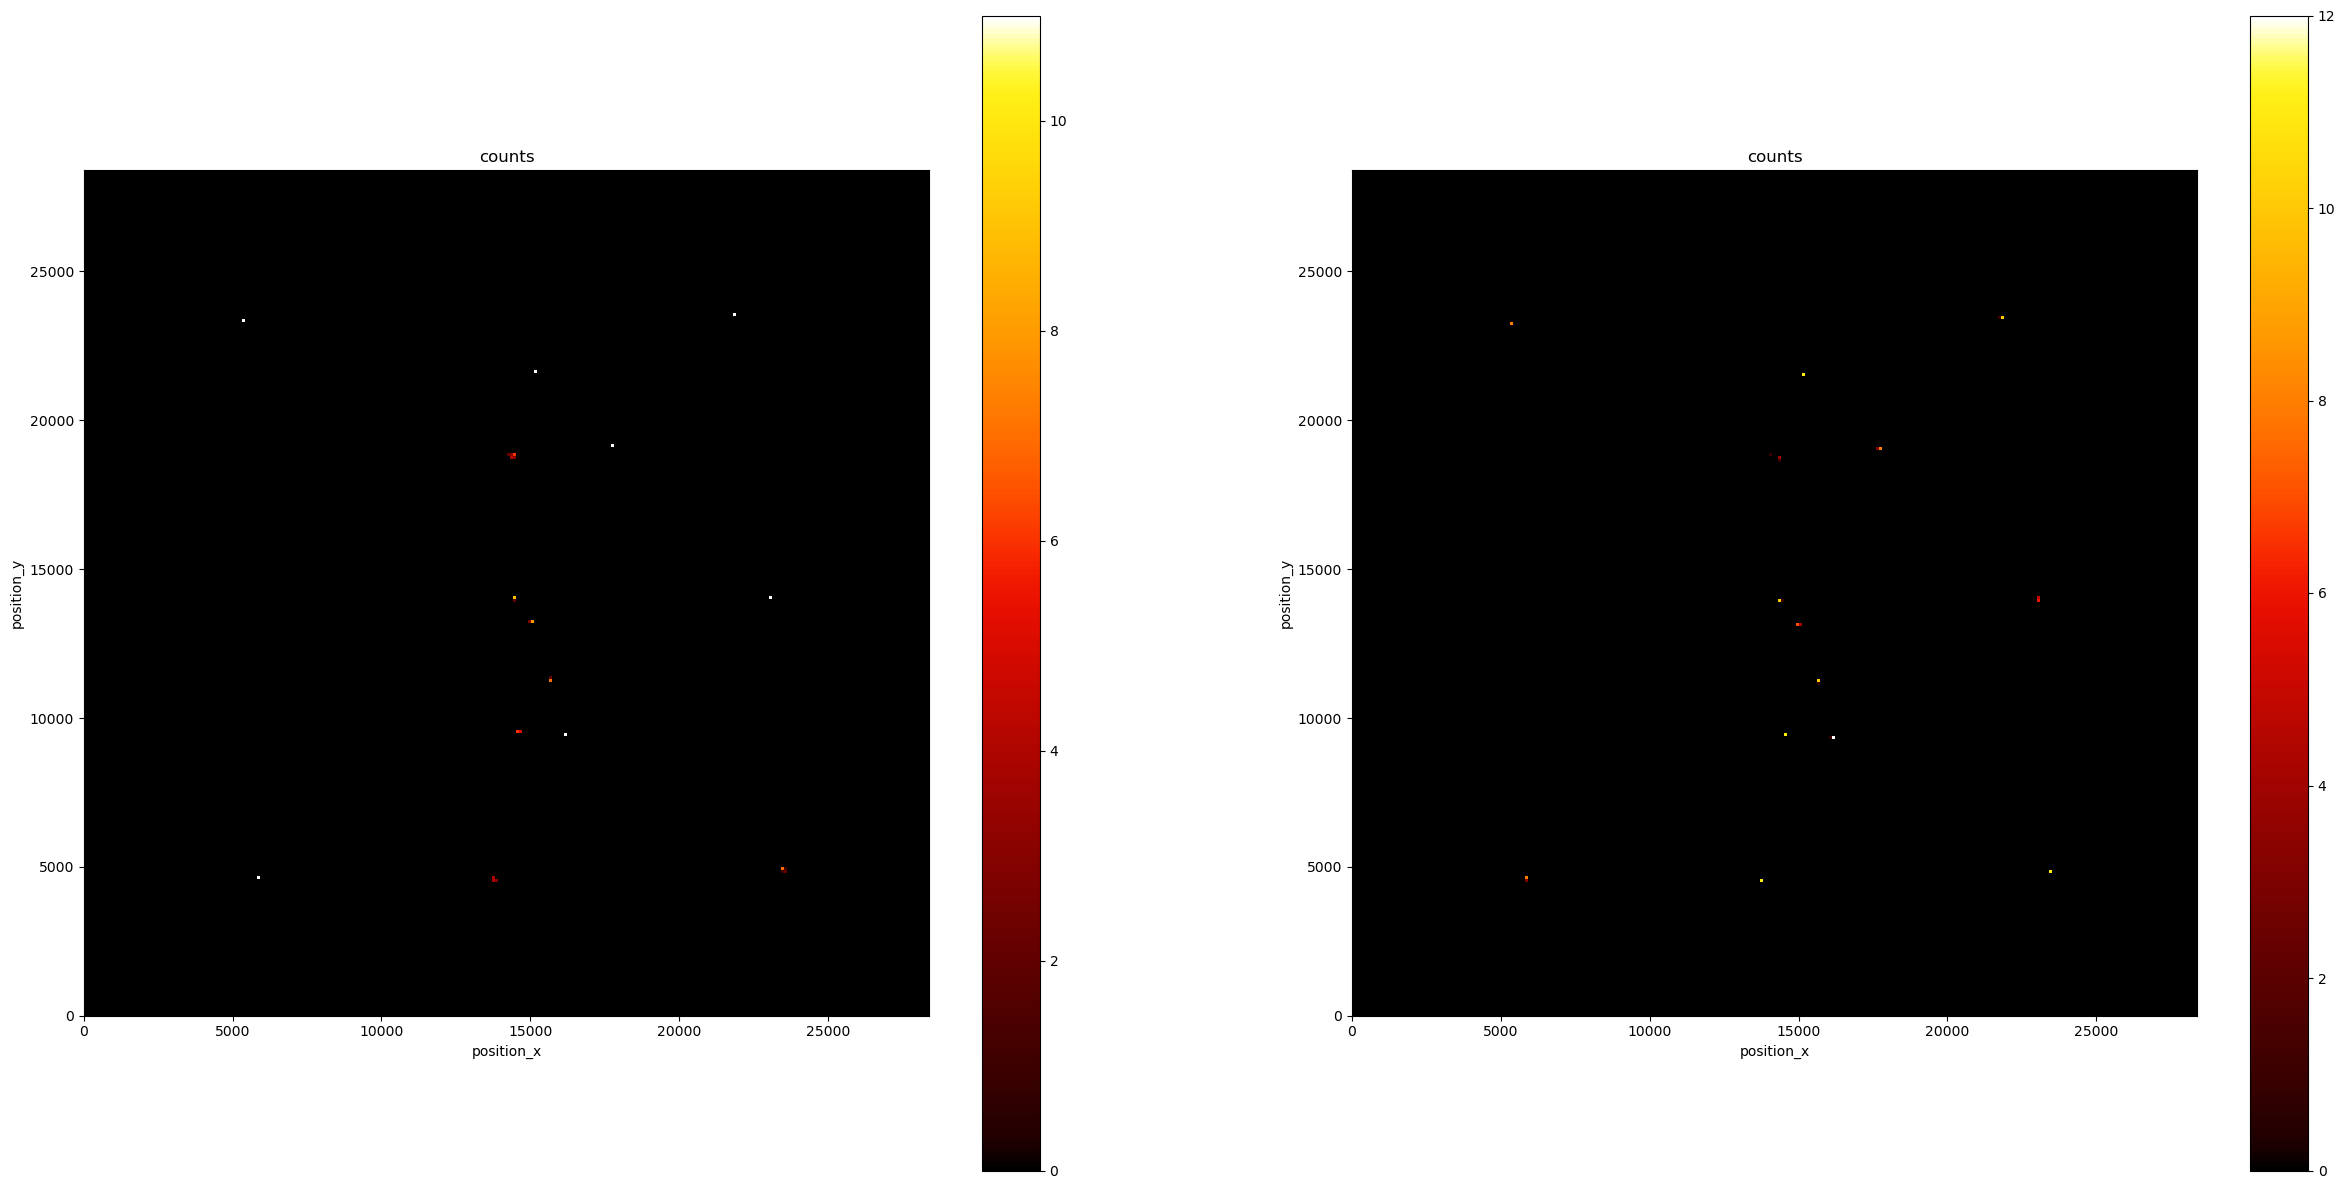

In [11]:
plt.style.use('default')
fig, axes = plt.subplots(1, 2, figsize=(30, 15))
lc.render_2d_mpl(beads_532, loc_properties=['position_x', 'position_y'], ax= axes[0], bin_size=(100, 100), bin_range=(0, 28416));
lc.render_2d_mpl(beads_640, loc_properties=['position_x', 'position_y'], ax= axes[1], bin_size=(100, 100), bin_range=(0, 28416));

In [12]:
viewer = napari.Viewer(ndisplay=3)

In [13]:
prob_width = 30 # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': beads_640.data.position_z,
        'position_x': beads_640.data.position_x,
        'position_y': beads_640.data.position_y,

    })

colors = beads_640.data.frame.to_numpy()
colors_norm = (colors-np.min(colors))/(np.max(colors)-np.min(colors))

prob = beads_640.data.locprecnm.to_numpy()#*111
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1

point_features = {
    'z_value': colors_norm,
    'prob': prob.tolist(),
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='z_value', face_colormap= 'turbo', border_color='z_value', border_colormap='turbo', size=prob_width, name= '640 raw')
#viewer.dims.order = (2,0,1)

<Points layer '640 raw' at 0x23829779d30>

In [14]:
prob_width = 30 # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': beads_532.data.position_z,
        'position_x': beads_532.data.position_x,
        'position_y': beads_532.data.position_y,

    })

colors = beads_532.data.frame.to_numpy()
colors_norm = (colors-np.min(colors))/(np.max(colors)-np.min(colors))

prob = beads_532.data.locprecnm.to_numpy()#*111
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1

point_features = {
    'z_value': colors_norm,
    'prob': prob.tolist(),
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='z_value', face_colormap= 'turbo', border_color='z_value', border_colormap='turbo', size=prob_width, name= '532 raw')
#viewer.dims.order = (2,0,1)

<Points layer '532 raw' at 0x2381f312c10>

# 3. Generate alignment matrix

In [17]:
matrix = lc.register_icp(beads_532,beads_640)

RegistrationResult with fitness=1.000000e+00, inlier_rmse=4.388940e+01, and correspondence_set size of 159
Access transformation to get result.


# 4. Display aligned beads

In [19]:
sample_coordinates_1 = beads_532.data[["position_x", "position_y", "position_z"]].to_numpy()
corrected_sample_coordinates_1 = np.matmul(sample_coordinates_1, matrix.matrix) + matrix[1]
corrected_sample_coordinates_1
x_coordinates = corrected_sample_coordinates_1[:, 0].tolist()
y_coordinates = corrected_sample_coordinates_1[:, 1].tolist()
z_coordinates = corrected_sample_coordinates_1[:, 2].tolist()
beads_532_aligned = beads_532.data.drop(["position_x", "position_y", "position_z"], axis=1)
beads_532_aligned.insert(loc=0, column="position_x", value=x_coordinates)
beads_532_aligned.insert(loc=1, column="position_y", value=y_coordinates)
beads_532_aligned.insert(loc=2, column="position_z", value=z_coordinates)
beads_532_aligned = lc.LocData.from_dataframe(dataframe=beads_532_aligned)

In [20]:
viewer = napari.Viewer(ndisplay=3)

In [21]:
prob_width = 60 # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': beads_532_aligned.data.position_z,
        'position_x': beads_532_aligned.data.position_x,
        'position_y': beads_532_aligned.data.position_y,

    })


points = coordinates.to_numpy()

viewer.add_points(points, symbol='o',  face_color= 'orange',  border_color='orange', size=90, name= '532 aligned')
#viewer.dims.order = (2,0,1)

<Points layer '532 aligned' at 0x2381e32c7d0>

In [22]:
prob_width = 60 # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': beads_532.data.position_z,
        'position_x': beads_532.data.position_x,
        'position_y': beads_532.data.position_y,

    })


points = coordinates.to_numpy()

viewer.add_points(points, symbol='o',  face_color= 'green',  border_color='green', size=90, name= '532 raw')
#viewer.dims.order = (2,0,1)

<Points layer '532 raw' at 0x238503d6ad0>

In [23]:
prob_width = 60 # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': beads_640.data.position_z,
        'position_x': beads_640.data.position_x,
        'position_y': beads_640.data.position_y,

    })


points = coordinates.to_numpy()

viewer.add_points(points, symbol='o',  face_color= 'red',  border_color='red', size=90, name= '640 raw')
#viewer.dims.order = (2,0,1)

<Points layer '640 raw' at 0x2381e146710>

# 5. Save alignment matrix and offset

In [24]:
matrix_path = Path(directory / Path("alignment_matrix.npy"))
offset_path = Path(directory / Path("offset_matrix.npy"))
np.save(matrix_path, matrix.matrix)
np.save(offset_path, matrix.offset)